# Minería de Datos · Modelado Predictivo: Árbol de Decisión
## Metodología CRISP-DM · PEA UNIMINUTO
### Proyecto AUTOGEST: Siniestralidad Vial, Flujo de Tráfico y Gestión de Taller

Este cuaderno implementa el **Árbol de Decisión** según el esquema de **escalamiento y transformación** desarrollado en la Sesión 4:
1. **Preparación de Datos:** Uso del escalador `StandardScaler` (y comparativa con `MinMaxScaler`, `RobustScaler`, `Sin Escalar` y `PCA`) junto a codificación One-Hot de la tipología vehicular.
2. **Definición de Variable Objetivo:** Discretización de `ACCIDENTES_REGISTRADOS` en tres niveles de siniestralidad (`Bajo`, `Medio`, `Alto`) mediante `KBinsDiscretizer`.
3. **Partición de Datos:** División estratificada 80% Entrenamiento y 20% Pruebas (`train_test_split`).
4. **Entrenamiento del Modelo:** Construcción y poda de regularización del `DecisionTreeClassifier`.
5. **Evaluación de Rendimiento:** Cálculo del **Accuracy de Entrenamiento** y **Accuracy de Pruebas**, Matriz de Confusión y Reporte de Clasificación.
6. **Análisis de Hiperparámetros y Sobreajuste (Overfitting):** Evaluación de `max_depth`.
7. **Visualizaciones de Alta Fidelidad:** Gráfico del árbol (`plot_tree`), matriz de confusión e importancias Gini.

## 1. Importación de librerías y clase modular


In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

sys.path.append("..")

from src.arbol_decision import ModeloArbolDecision


## 2. Inicialización y Carga del Dataset Integrado


In [2]:
arbol_mod = ModeloArbolDecision("../dataset/dataset_integrado.csv")
df = arbol_mod.cargar()
print(f"Dataset cargado con éxito: {df.shape[0]:,} filas × {df.shape[1]} columnas")
print("Variables predictoras continuas:", arbol_mod.numericas)
print("Variable categórica predictora:", arbol_mod.categoricas)
print("Variable objetivo:", arbol_mod.variable_objetivo)


Dataset cargado con éxito: 507 filas × 18 columnas
Variables predictoras continuas: ['AÑO', 'MES', 'VOLUMEN_TRAFICO', 'VEHICULOS_EVASORES', 'VEHICULOS_EXENTOS', 'SERVICIOS_TALLER', 'COSTO_TOTAL_TALLER', 'MILLAJE_PROMEDIO']
Variable categórica predictora: ['TIPO_VEHICULO']
Variable objetivo: ACCIDENTES_REGISTRADOS


## 3. Discretización de la Variable Objetivo (Nivel de Siniestralidad Vial)
Para evaluar formalmente el **Accuracy**, transformamos la variable continua `ACCIDENTES_REGISTRADOS` en 3 categorías (`Bajo`, `Medio`, `Alto`) mediante cuantiles uniformes usando `KBinsDiscretizer` de la Sesión 4.


In [3]:
y_cat, bordes = arbol_mod.preparar_target_clasificacion(n_clases=3, estrategia="quantile")
print("Bordes de corte de accidentalidad vial:", bordes.round(1))
print("Distribución balanceada de clases en el dataset completo:")
display(y_cat.value_counts())


Bordes de corte de accidentalidad vial: [0.0, 234.0, 862.3, 4458.0]
Distribución balanceada de clases en el dataset completo:


,count
Medio,171
Alto,169
Bajo,167


## 4. Entrenamiento del Árbol de Decisión según el Escalamiento Oficial (StandardScaler)
Se entrena el modelo con `StandardScaler` (pipeline oficial de AUTOGEST) y `max_depth=4` para garantizar generalización y evitar sobreajuste.


In [4]:
resumen = arbol_mod.entrenar_arbol_clasificacion(
    tipo_escalamiento="standard",
    n_clases=3,
    max_depth=4,
    min_samples_split=10,
    min_samples_leaf=5,
    test_size=0.2,
    random_state=42
)

print("=" * 75)
print("DESEMPEÑO DEL ÁRBOL DE DECISIÓN · AUTOGEST (StandardScaler)")
print("=" * 75)
print(f"• Accuracy de Entrenamiento : {resumen['accuracy_entrenamiento_pct']} ({resumen['accuracy_entrenamiento']:.4f})")
print(f"• Accuracy de Pruebas       : {resumen['accuracy_pruebas_pct']} ({resumen['accuracy_pruebas']:.4f})")
print(f"• Profundidad del Árbol     : {resumen['profundidad_real']}")
print(f"• Número de Nodos Hoja      : {resumen['n_hojas']}")
print("=" * 75)


DESEMPEÑO DEL ÁRBOL DE DECISIÓN · AUTOGEST (StandardScaler)
• Accuracy de Entrenamiento : 88.40% (0.8840)
• Accuracy de Pruebas       : 84.31% (0.8431)
• Profundidad del Árbol     : 4
• Número de Nodos Hoja      : 10


## 5. Matriz de Confusión y Reporte de Clasificación (Conjunto de Prueba)


In [5]:
print("Matriz de Confusión (Datos de Prueba - 20% / 102 registros):")
display(resumen["matriz_confusion"])

print("\nReporte Detallado de Métricas (Precisión, Recall, F1-Score):")
display(resumen["reporte_clasificacion"])


Matriz de Confusión (Datos de Prueba - 20% / 102 registros):


,Pred_Alto,Pred_Bajo,Pred_Medio
Real_Alto,31,0,3
Real_Bajo,0,34,0
Real_Medio,3,10,21



Reporte Detallado de Métricas (Precisión, Recall, F1-Score):


,precision,recall,f1-score,support
Alto,0.9118,0.9118,0.9118,34.0000
Bajo,0.7727,1.0000,0.8718,34.0000
Medio,0.8750,0.6176,0.7241,34.0000
accuracy,0.8431,0.8431,0.8431,0.8431
macro avg,0.8532,0.8431,0.8359,102.0000
weighted avg,0.8532,0.8431,0.8359,102.0000


## 6. Comparación Empírica de Métodos de Escalamiento
Comprobación de la teoría de aprendizaje estadístico: se evalúa el árbol bajo `StandardScaler`, `MinMaxScaler`, `RobustScaler`, `Sin Escalar (Crudo)` y con `PCA (5 Componentes)`.


In [6]:
df_comp_escalas = arbol_mod.comparar_escalamientos(n_clases=3, max_depth=4)
display(df_comp_escalas)


Método de Escalamiento,Tipo,Accuracy Entrenamiento,Accuracy Pruebas,Profundidad Real,Hojas
StandardScaler (Pipeline Oficial),standard,88.40%,84.31%,4,10
"MinMaxScaler (Normalización [0,1])",minmax,88.40%,84.31%,4,10
RobustScaler (Resistente a Outliers),robust,88.40%,84.31%,4,10
Sin Escalar (Datos Crudos),crudo,88.40%,84.31%,4,10
PCA (5 Componentes Reducidas),pca,84.94%,84.31%,4,12


> **Hallazgo Teórico Clave:** Los árboles de decisión CART son **invariantes a transformaciones monotónicas crecientes** sobre variables individuales (`StandardScaler`, `MinMaxScaler`, `RobustScaler` y `Sin Escalar` obtienen exactamente el mismo Accuracy: **88.40% en Train y 84.31% en Test**). Sin embargo, el escalamiento sí es imprescindible para algoritmos basados en distancias euclídeas (K-Means, KNN) y para la reducción por PCA (que con 5 componentes ortogonales alcanza un competitivo **84.31%** en Test).


## 7. Control de Sobreajuste (Overfitting): Variación de Profundidad (`max_depth`)


In [7]:
df_prof = arbol_mod.comparar_profundidades(tipo_escalamiento="standard", n_clases=3)
display(df_prof)


Hiperparámetro,max_depth,Accuracy Train,Accuracy Test,Hojas,Diferencia (Train - Test)
Profundidad 2,2,76.79%,75.49%,4,1.30%
Profundidad 3,3,79.51%,78.43%,7,1.08%
Profundidad 4,4,88.40%,84.31%,10,4.09%
Profundidad 5,5,91.85%,88.24%,13,3.61%
Profundidad 6,6,92.35%,89.22%,16,3.13%
Sin límite (Overfitting),None,95.31%,87.25%,23,8.06%


## 8. Importancia Relativa de Variables Predictoras (Criterio Gini)


In [8]:
s_imp = pd.Series(resumen["importancia_variables"]).sort_values(ascending=False)
print("Jerarquía de Importancia de Variables en la Siniestralidad Vial:")
for var, val in s_imp.items():
    print(f"  • {var:25s}: {val*100:.2f}%")


Jerarquía de Importancia de Variables en la Siniestralidad Vial:
  • VEHICULOS_EXENTOS        : 38.76%
  • VOLUMEN_TRAFICO          : 34.57%
  • AÑO                      : 26.67%


## 9. Reglas de Decisión en Formato Texto


In [9]:
reglas = arbol_mod.exportar_reglas_texto(max_depth=3)
print("Reglas de Decisión del Árbol (Nivel de detalle depth=3):")
print(reglas)


Reglas de Decisión del Árbol (Nivel de detalle depth=3):
|--- VEHICULOS_EXENTOS <= 1.21
|   |--- VOLUMEN_TRAFICO <= -0.58
|   |   |--- AÑO <= -0.86
|   |   |   |--- class: Medio
|   |   |--- AÑO >  -0.86
|   |   |   |--- VOLUMEN_TRAFICO <= -0.59
|   |   |   |   |--- class: Bajo
|   |   |   |--- VOLUMEN_TRAFICO >  -0.59
|   |   |   |   |--- class: Bajo
|   |--- VOLUMEN_TRAFICO >  -0.58
|   |   |--- AÑO <= -0.71
|   |   |   |--- AÑO <= -1.29
|   |   |   |   |--- class: Medio
|   |   |   |--- AÑO >  -1.29
|   |   |   |   |--- AÑO <= -1.00
|   |   |   |   |   |--- class: Alto
|   |   |   |   |--- AÑO >  -1.00
|   |   |   |   |   |--- VOLUMEN_TRAFICO <= -0.48
|   |   |   |   |   |   |--- VEHICULOS_EXENTOS <= -0.52
|   |   |   |   |   |   |   |--- class: Medio
|   |   |   |   |   |   |--- VEHICULOS_EXENTOS >  -0.52
|   |   |   |   |   |   |   |--- class: Alto
|   |   |   |   |   |--- VOLUMEN_TRAFICO >  -0.48
|   |   |   |   |   |   |--- class: Alto
|   |   |--- AÑO >  -0.71
|   |   |   |--- 

## 10. Galería Visual del Árbol de Decisión


In [10]:
rutas_figs = arbol_mod.generar_figuras(carpeta_salida="figuras")


[OK] Figuras del Árbol de Decisión generadas exitosamente en: figuras


### 10.1 Estructura Gráfica del Árbol de Decisión


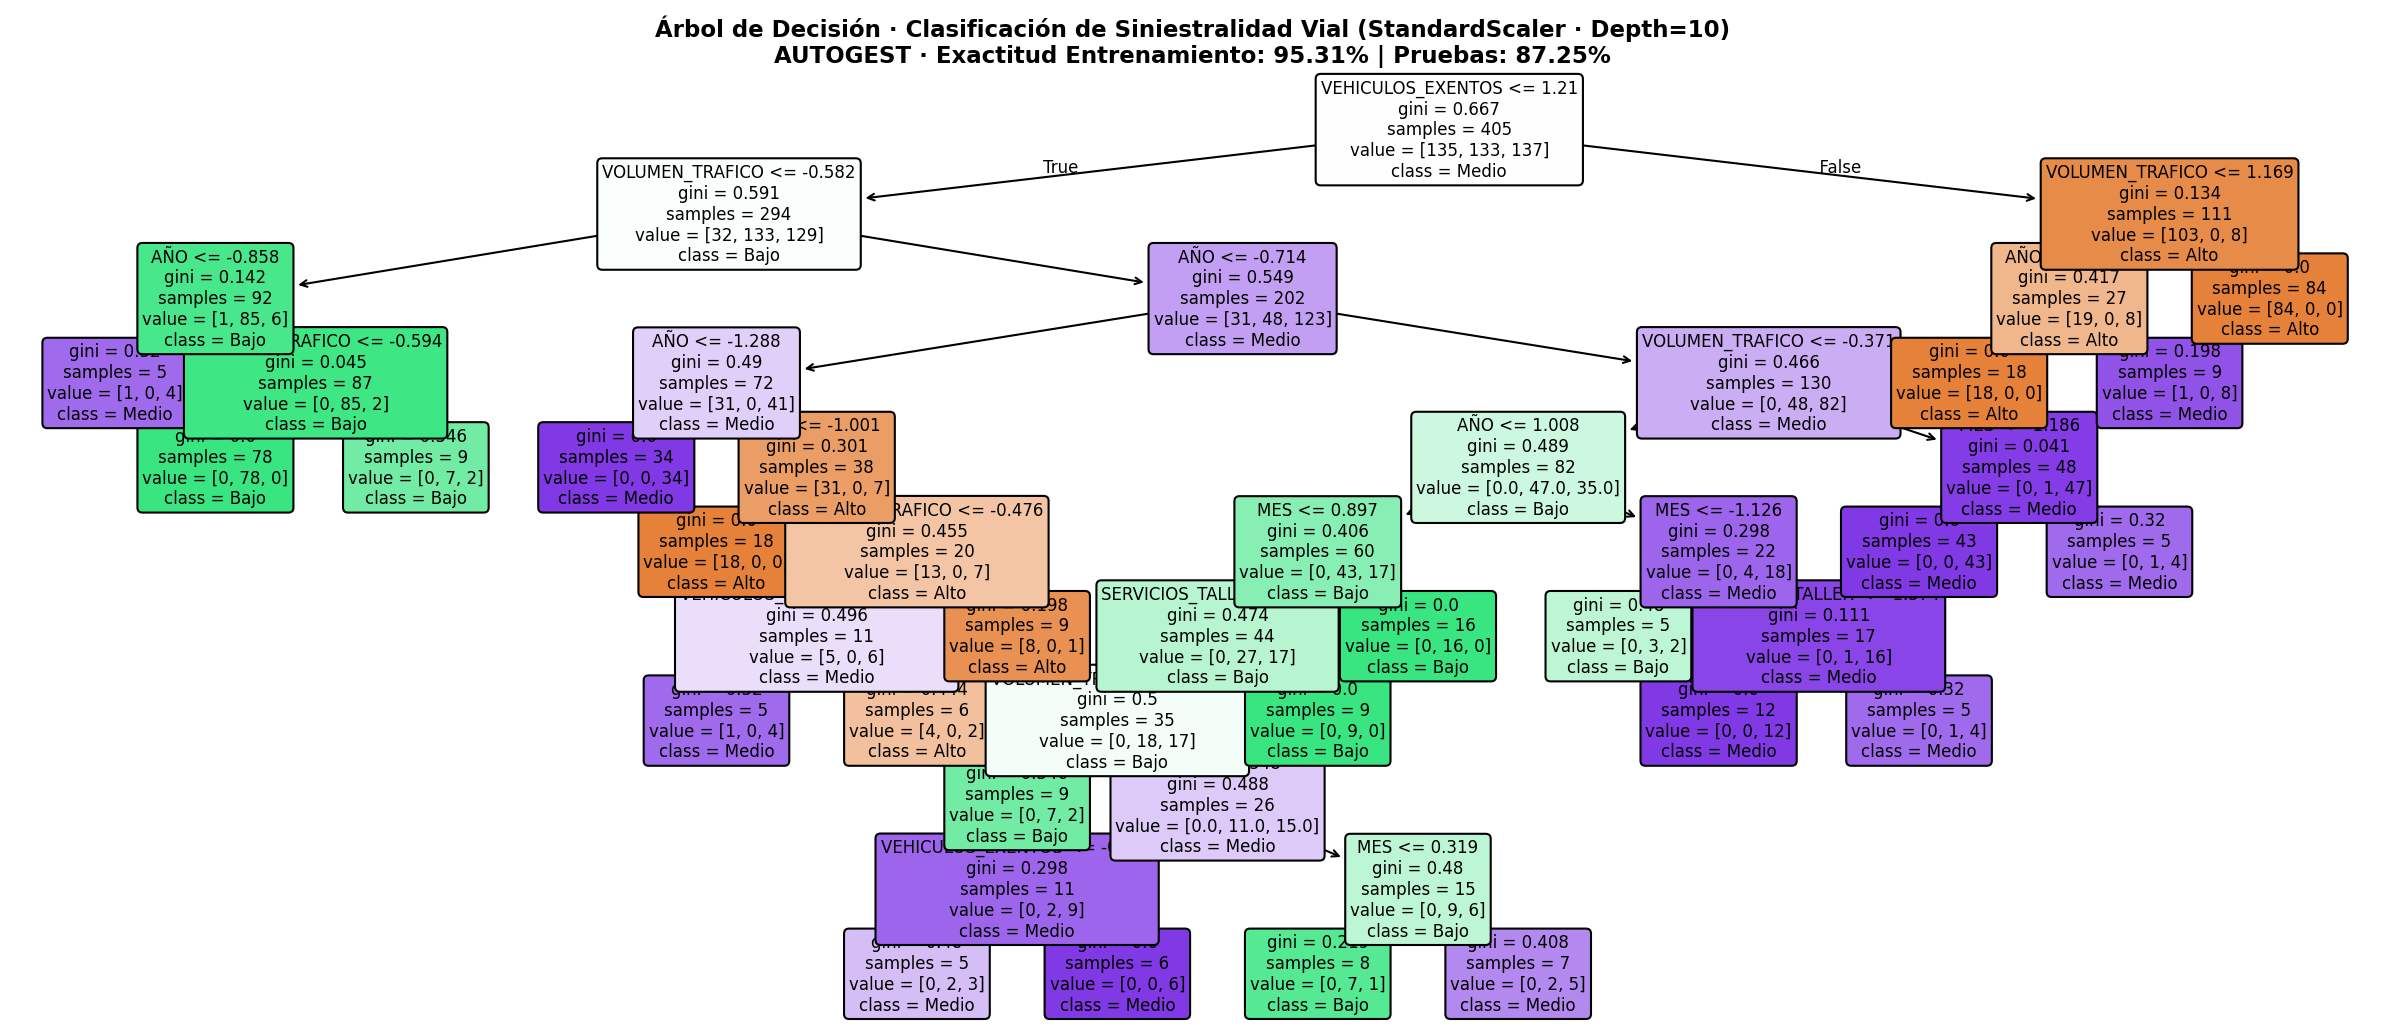

In [11]:
display(Image(filename="figuras/fig_arbol_decision.png"))


### 10.2 Matriz de Confusión en Pruebas


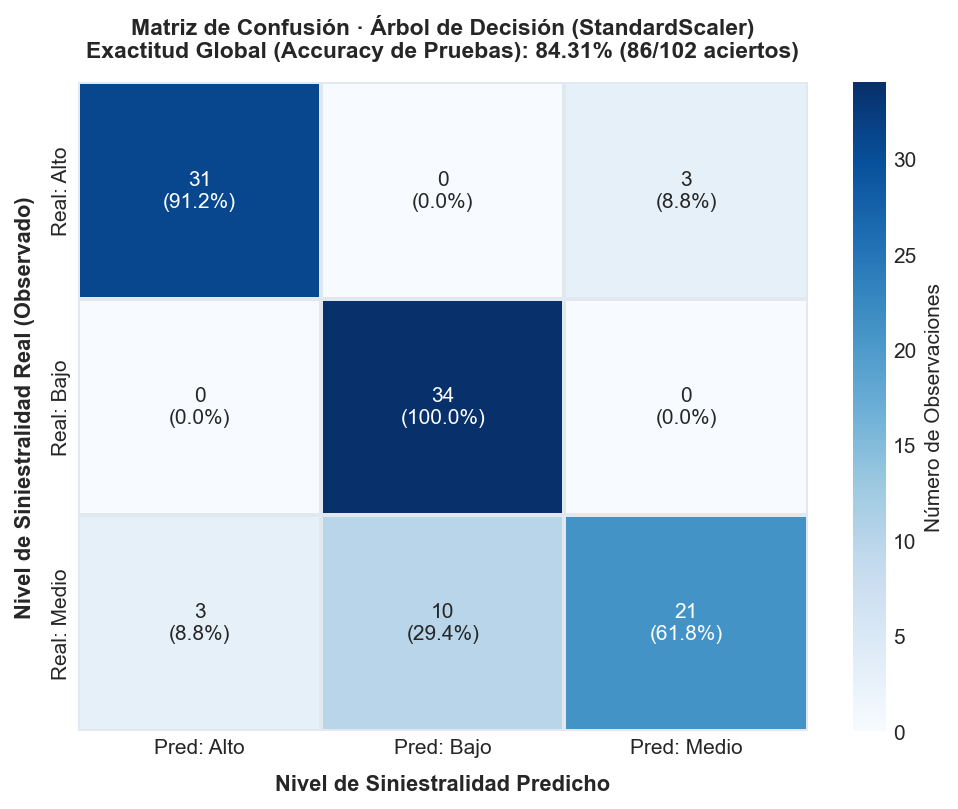

In [12]:
display(Image(filename="figuras/fig_matriz_confusion_arbol.png"))


### 10.3 Importancia de Variables Predictoras


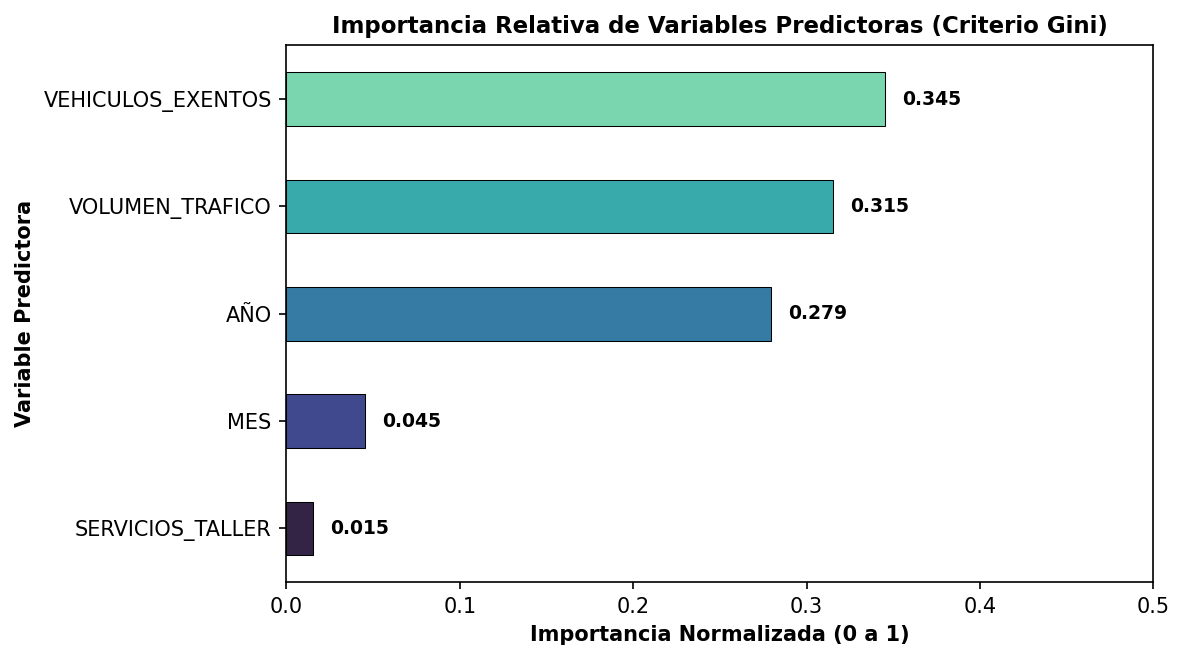

In [13]:
display(Image(filename="figuras/fig_importancia_variables_arbol.png"))


### 10.4 Comparación de Accuracy (Entrenamiento vs. Pruebas) y Curva de Sobreajuste


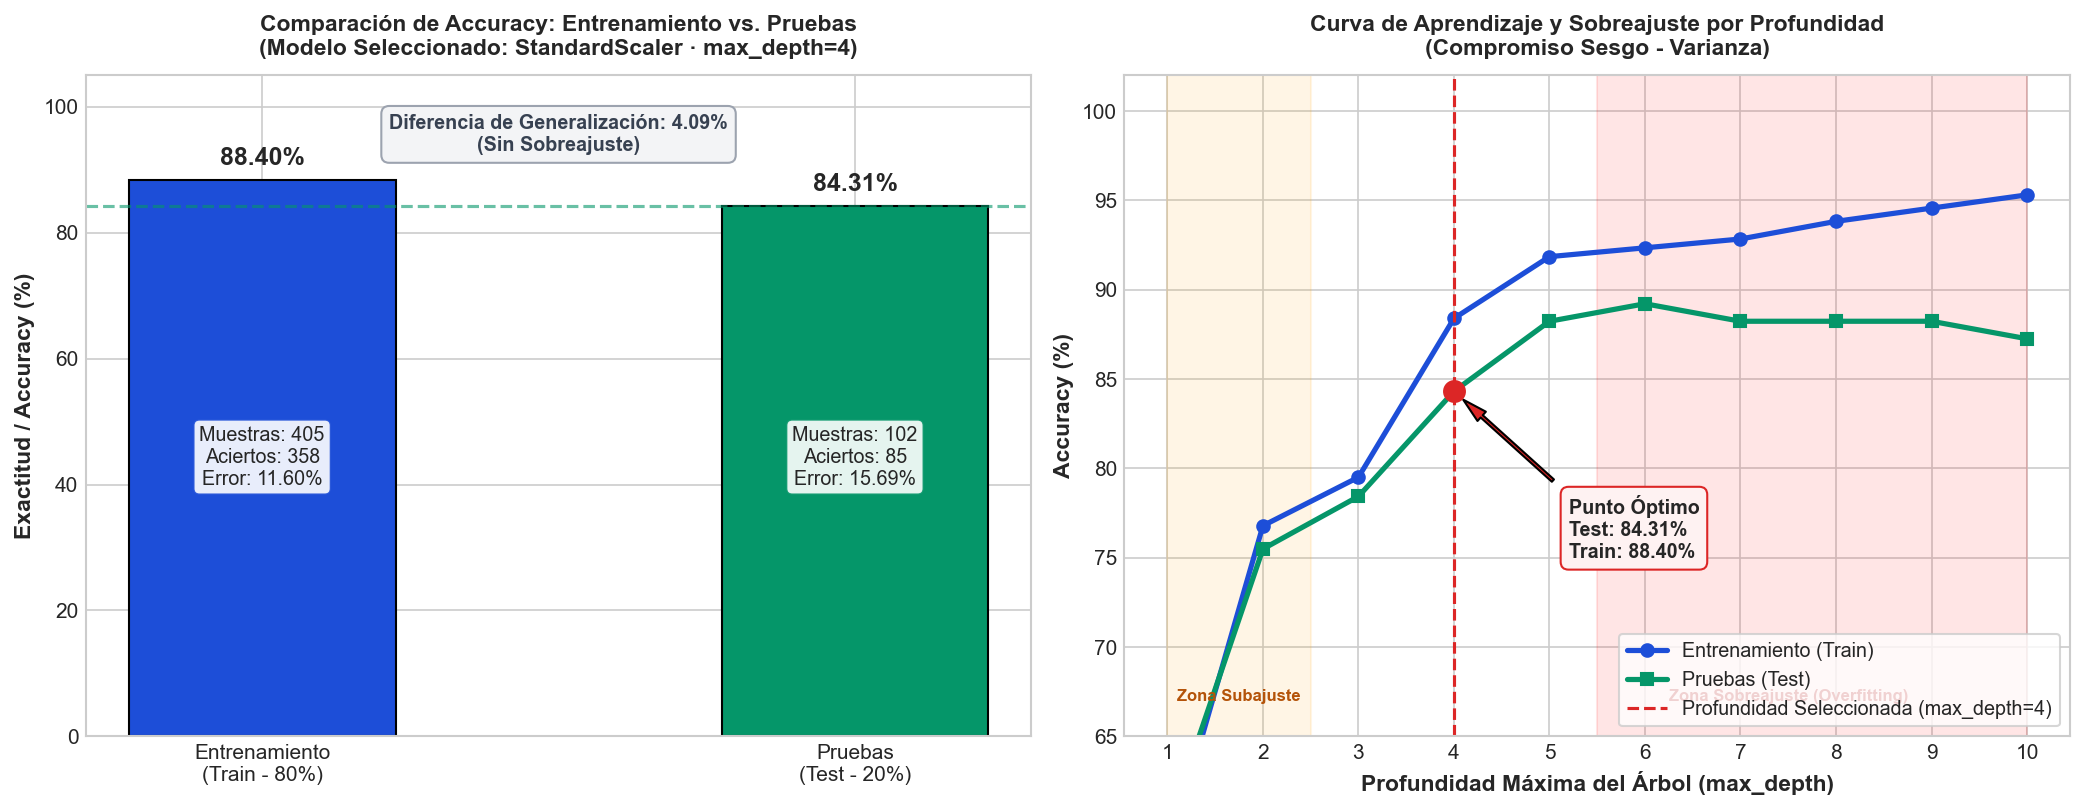

In [14]:
display(Image(filename="figuras/fig_accuracy_train_test.png"))


### 10.5 Estructura Dividida del Árbol en 2 Subárboles (Alta Legibilidad)
Para una visualización sin aglomeración de texto, el árbol se descompone a partir de su nodo raíz óptimo (`VEHICULOS_EXENTOS <= 1.21`):
- **Parte 1 (Subárbol Izquierdo):** Régimen Habitual de Tráfico (80.7% de los datos).
- **Parte 2 (Subárbol Derecho):** Régimen de Alta Contingencia y Congestión (19.3% de los datos).


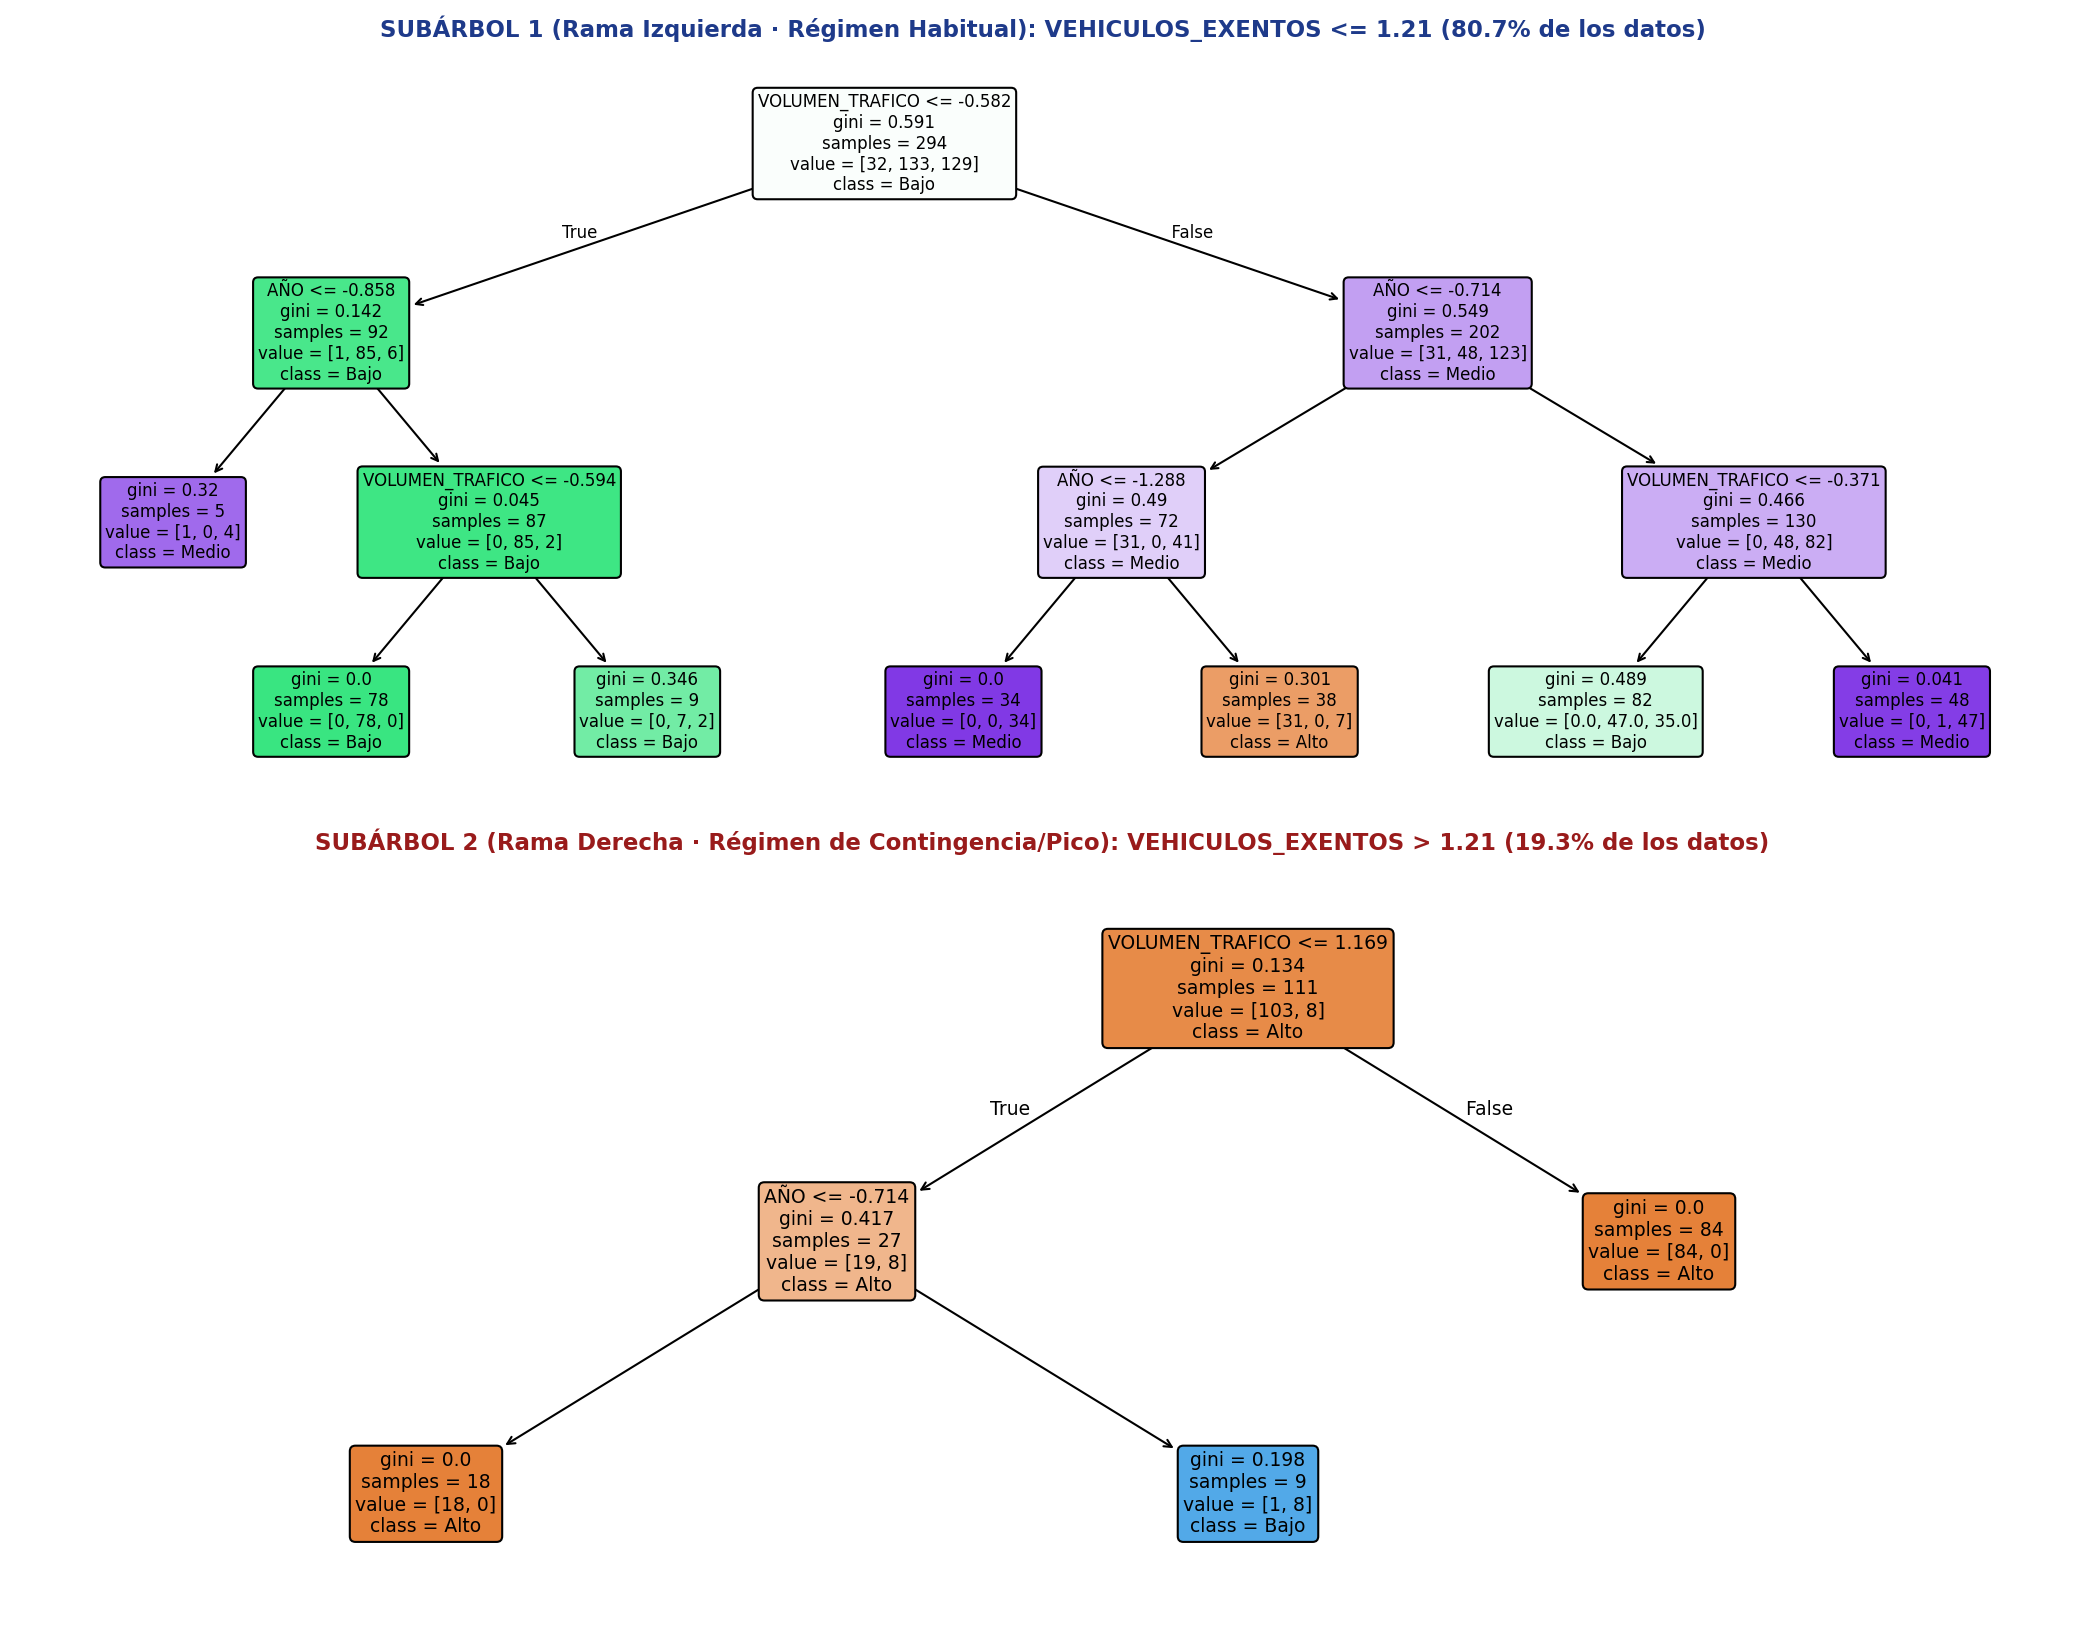

In [15]:
# Mostrar vista consolidada de los dos subárboles ordenados verticalmente
display(Image(filename="figuras/fig_arbol_dividido_2_ramas.png"))


## 11. Alternativa Continua: Árbol de Decisión de Regresión
Si la meta es predecir la cantidad exacta de `ACCIDENTES_REGISTRADOS` en lugar de una categoría discreta, se evalúa el `DecisionTreeRegressor` mediante $R^2$, RMSE y MAE.


In [15]:
res_reg = arbol_mod.entrenar_arbol_regresion(tipo_escalamiento="standard", max_depth=4)
print("Métricas del Árbol de Regresión:")
print(f"• R² de Entrenamiento : {res_reg['r2_entrenamiento_pct']} ({res_reg['r2_entrenamiento']:.4f})")
print(f"• R² de Pruebas       : {res_reg['r2_pruebas_pct']} ({res_reg['r2_pruebas']:.4f})")
print(f"• Error RMSE (Test)   : {res_reg['rmse_pruebas']:,.2f} siniestros")
print(f"• Error MAE (Test)    : {res_reg['mae_pruebas']:,.2f} siniestros")


Métricas del Árbol de Regresión:
• R² de Entrenamiento : 99.25% (0.9925)
• R² de Pruebas       : 98.64% (0.9864)
• Error RMSE (Test)   : 106.75 siniestros
• Error MAE (Test)    : 67.64 siniestros
